<img src="./logo_UTN.svg" align="right" width="150" /> 

#### Teoría de Circuitos II - R4001

# INFORME UNIFICADO DE LABORATORIO

Autor: Nicolás Burgos


## LABORATORIO N°1: TEORÍA MODERNA Y FILTRADO ACTIVO

### OBJETIVOS:

- Consolidar los conceptos de teoría moderna mediante la implementación circuital.

- Simular e implementar el filtro con componentes activos OPAMP/OTA.

- Medir las partes de la función transferencia en un ancho de banda de 10 a 100 kHz.

- Diseñar el PCB en Altium / KiCad para optimizar los resultados de la medición.

### DESCRIPCIÓN:

Este trabajo práctico de Laboratorio tiene como objeto la implementación y medición de un filtro activo que cumpla con los requerimientos de una plantilla, partiendo el diseño en 3 secciones detalladas a continuación.

### PLANTILLA SOLICITADA:

![alt text](plantilla_labo1.png)

### PARTE 1: ANÁLISIS Y SIMULACIÓN

1. Obtenga el orden del filtro y el $\epsilon$ cuando corresponda.

2. Hallar la función transferencia. Analizar posibles normas de Impedancia y frecuencia.

3. Obtener la Transferencia del circuito a implementar.

4. Realice una simulación numérica/simbólica de la función transferencia.

5. Realice la simulación circuital. Incluya el modelo real del OPAMP/OTA.

6. En ambos casos obtener las gráficas de módulo, fase y retardo.

### PARTE 2: ARMADO DEL CIRCUITO

1. Armar el diseño del PCB en Altium o KiCad.

2. Usar conectores, headers o borneras para poder alimentar el filtro, introducir la señal de entrada, medir la señal de entrada y salida ( *test points* ) convenientemente.

3. Utilizar un zócalo DIP 14 para colocar el OPAMP y DIP 16 para el OTA.

4. Incluir resistores variables ( presets / trimmer ) o bien resistores fijos con tolerancias del 1%.

5. En los puntos de alimentación del circuito integrado agregar capacitores de bypass. Se sugiere agregar un capacitor electrolítico o de poliéster entre $1 \mu F$ a $100 \mu F$ con otro cerámico de $100 nF$ a $470 nF$ en paralelo para reducir el ruido de la fuente.

### PARTE 3: MEDICIÓN EN EL LABORATORIO

El día de la práctica contarán con el instrumental y los cables de conexión. El Setup de medición se detalla a continuación:

![alt text](setup_labo1.png)

1. Verifique visualmente y con el multímetro que su circuito no tiene cortocircuitos y que los componentes estén correctamente soldados. 

2. Utilice la limitación de corriente de la fuente en algunas decenas de mA. Para ello se debe poner en corto los bornes de + y - a una tensión baja por ejemplo 1 V. De esta manera el equipo entra en modo CC ( corto circuito ) y se puede setear el nivel de corriente.

3. Setear la tensión de la fuente. Utilice un multímetro para ajustar la tensión de la fuente. Finalmente alimente su circuito.  Tenga en cuenta que la medición mejora para niveles más altos de fuente.

4. Verifique las puntas del osciloscopio. Utilice la señal de prueba tanto en el canal 1 como 2 para ajustar la respuesta temporal visualizada. Verifique el valor de AC y periodo de esta señal de prueba con los medidores del DSO.

5. Calibre una señal senoidal en el generador a un nivel que optimice la medición en la banda de paso de  valor medio nulo con el generador. Tenga en cuenta que el filtro puede generar sobretensiones a la salida.

6. Desenergice el circuito si así estuviera y conecte el integrado. Conecte la alimentación nuevamente y el generador de entrada. Verifique que el DSO tenga señal a la salida. Debe ser de la misma forma ( sin distorsión ) que la entrada con una cierta fase y alguna diferencia de amplitud probablemente.

7. Llegado a este punto está en condiciones de realizar un barrido con frecuencia.

## DESARROLLO DE LABORATORIO

### PARTE 1: ANÁLISIS Y SIMULACIÓN

Debido a las frecuencias de corte y de stop propuestas en el enunciado, podemos determinar que el filtro pedido se trata de un Pasa Altos. Ante ello, la plantilla estimada será la siguiente:

![alt text](diag_plant_labo1.png)

\begin{equation}
\alpha_{MIN} = 30 \ dB \ ; \ \alpha_{MAX} = 1 \ dB \ ; \ f_p = f_c = 300 \ Hz \ ; \ f_s = 100 \ Hz
\end{equation}

El siguiente paso será determinar el ripple en banda de paso del filtro, para lo que hacemos uso de la atenuación máxima en banda de paso, es decir, $\alpha_{MAX} = 1 \ dB$. De esta forma:

\begin{equation}
\alpha_{MAX} = 10 \cdot log_{10}( \epsilon^2 + 1 )
\end{equation}

\begin{equation}
\boxed{\epsilon^2 = 10^{ \frac{\alpha_{MAX}}{10} } - 1 = 0,2589}
\end{equation}

\begin{equation}
\boxed{\epsilon = 0,5089}
\end{equation}

Luego, debemos establecer el orden del filtro a diseñar. Para ello, planteamos lo siguiente:

\begin{equation}
\alpha_n = 10 \cdot log_{10}[ 1 + \epsilon^2 \cdot cosh^2[ n \cdot cosh^{-1}( \omega_s ) ] ] \geq \alpha_{MIN}
\end{equation}

Donde tendremos $\omega_s = \frac{2 \pi f_s}{2 \pi f_p} = 3$. Así, iterando para diferentes valores de "n", buscamos cumplir con la anterior desigualdad, obteniendo:

\begin{equation}
\alpha_1 = 5,2246 \ dB < \alpha_{MIN}
\end{equation}

\begin{equation}
\alpha_2 = 14,798 \ dB < \alpha_{MIN}
\end{equation}

\begin{equation}
\alpha_3 = 34,0457 \ dB > \alpha_{MIN}
\end{equation}

\begin{equation}
\boxed{n = 3}
\end{equation}

Con estos datos, ya podemos plantear la expresión del cuadrádo del módulo de la respuesta en frecuencia de la transferencia buscada para el diseño, recordando que $C_3(\omega) = 4 \omega^3 - 3 \omega$.

\begin{equation}
|T(j\omega)|^2 = \frac{1}{1 + \epsilon^2 \cdot C_3^2(\omega)} = \frac{1}{1 + \epsilon^2 \cdot (4 \omega^3 - 3 \omega)^2} = \frac{1}{1 + \epsilon^2 \cdot (16 \omega^6 - 24 \omega^4 + 9 \omega^2)}
\end{equation}

\begin{equation}
|T(j\omega)|^2 = \frac{ \frac{1}{16 \epsilon^2} }{ \omega^6 - \frac{3}{2} \omega^4 + \frac{9}{16} \omega^2 + \frac{1}{16 \epsilon^2} }
\end{equation}

Luego, realizando el reemplazo $\omega \to \frac{s}{j}$, podemos obtener:

\begin{equation}
|T(j\omega)|^2|_{\omega \to \frac{s}{j}} = T(S) \cdot T(-S) = \frac{ \frac{1}{16 \epsilon^2} }{ (\frac{S}{j})^6 - \frac{3}{2} (\frac{S}{j})^4 + \frac{9}{16} (\frac{S}{j})^2 + \frac{1}{16 \epsilon^2} }
\end{equation}

\begin{equation}
T(S) \cdot T(-S) = \frac{ \frac{1}{16 \epsilon^2} }{ -S^6 - \frac{3}{2} S^4 - \frac{9}{16} S^2 + \frac{1}{\epsilon^2} }
\end{equation}

Podremos ahora, imponer la forma que buscamos de la transferencia T(S), que será la de un Filtro Pasa Bajos de tercer orden, con lo que llegamos a lo siguiente:

\begin{equation}
T(S) = \frac{ c }{S^3 + aS^2 + bS + c} \ ; \ T(-S) = \frac{ c }{-S^3 + aS^2 - bS + c}
\end{equation}

\begin{equation}
T(S) \cdot T(-S) = \frac{ c^2 }{ -S^6 - (a^2 - 2b) S^4 - (2ac - b^2) S^2 + c^2 } = \frac{ \frac{1}{16 \epsilon^2} }{ -S^6 - \frac{3}{2} S^4 - \frac{9}{16} S^2 + \frac{1}{\epsilon^2} }
\end{equation}

Operando matemáticamente, igualando término semejantes, obtenemos los siguientes resultados:

\begin{equation}
\boxed{a = 0,9883 \ ; \ b = 1,2384 \ ; \ c = 0,4913}
\end{equation}

Conociendo estos valores, podemos proceder al armado de la función transferencia Pasa Bajos:

\begin{equation}
T(S)_{LPF} = \frac{ 0,4913 }{S^3 + 0,9883 \cdot S^2 + 1,1384 \cdot S + 0,4913}
\end{equation}

Sin embargo, como se pide en el enunciado, la transferencia que debemos buscar es una Pasa Altos, por lo que procedemos a realizar una transformación de la Pasa Bajos encontrada:

\begin{equation}
T(s)_{HPF} = T(S)_{LPF}|_{S = \frac{1}{s}} = \frac{ c }{ (\frac{1}{s})^3 + a (\frac{1}{s})^2 + b (\frac{1}{s}) + c}
\end{equation}

\begin{equation}
\boxed{T(s)_{HPF} = \frac{ s^3 }{s^3 + \frac{b}{c} \cdot s^2 + \frac{a}{c} \cdot s + \frac{1}{c}} = \frac{ s^3 }{s^3 + 2,5207 \cdot s^2 + 2,0116 \cdot s + 2,0354}}
\end{equation}

\begin{equation}
\boxed{T(s)_{HPF} = \frac{s^2}{s^2 + 0,497 \cdot s + 1,0058} \cdot \frac{s}{s + 2,0237} = \frac{s^2}{s^2 + \frac{1,0029}{2,0179} \cdot s + (1,0029)^2} \cdot \frac{s}{s + 2,0237}}
\end{equation}

En esta última expresión, podemos determinar las frecuencias de corte de cada sección ($\omega_1$, $\omega_2$), y el factor de selectividad (Q).

\begin{equation}
\omega_{01} = 1,0029 \ ; \ \omega_{02} = 2,0237 \ ; \ Q_1 = 2,0179
\end{equation}

Como podemos observar, la transferencia fue dividida en dos secciones, una de primer orden y otra de segundo orden. La forma de implementarlas será por medio de un circuito del tipo ACKERBERG-MOSSBERG para la seccion de segundo orden, y un filtro RC serie Pasa Altos para la de primer orden, redes las cuales se interconectarán en cascada. El circuito resultante será el siguiente:

![alt text](circ_labo1.png)

Puede observarse como la sección de segundo orden concatena varias de sus salidas en un Amplificador Operacional (OPAMP), generando una suma de funciones transferencias, que dan como resultado una transferencia bicuadrática, que responde a la siguiente expresión:

\begin{equation}
T(s)_{HPF} = \frac{ as^2 + s \cdot \frac{\omega_{01}}{Q_1} \cdot (a - b K Q_1) + \omega_{01}^2 \cdot [a - (c - d)K]}{s^2 + s \cdot \frac{\omega_{01}}{Q_1} + \omega_{01}^2}
\end{equation}

Observando la expresión obtenida más arriba de la transferencia, podemos asumir y determinar lo siguiente:

\begin{equation}
d = 0 \quad ; \quad a - b K Q_1 = 0 \quad ; \quad a - cK = 0
\end{equation}

Luego, considerando que nuestro filtro no tiene ganancia, podemos asumir que $a = K = 1$, y como $Q_1 = 2,0179$ entonces tendremos:

\begin{equation}
b = \frac{a}{K Q_1} = 0,496 \quad ; \quad c = \frac{a}{K} = 1
\end{equation}

Luego, analizando la sección de segundo orden mostrada en el circuito, y planteando las siguientes igualdades, podemos obtener la transferencia total:

\begin{equation}
R_3 = R_1 = R_4 = R_4 = R_5 = R_7 = R_8 = R_9 = R_{11} \quad ; \quad C_1 = C_2 = C_3
\end{equation}

\begin{equation}
T(s)_{HPF} = \frac{s^2}{s^2 + s \cdot \frac{1}{C_1 R_2} + \frac{1}{C_1^2 R_3^2}} \cdot \frac{s}{s + \frac{1}{C_1 R_10}}
\end{equation}

Podremos determinar a continuación los valores de $R_2$, $R_3$ y $R_10$, y asumiremos que $R_6 = \frac{R_{10}}{b}$:

\begin{equation}
Q_1 = \frac{R_2}{R_3} \to R_2 = R_3 \cdot Q_1 \quad ; \quad \omega_{02} = \frac{1}{C_1 \cdot R_{10}} \to R_{10} = \frac{1}{\omega_{02} \cdot C_1} \quad ; \quad \omega_{01} = \frac{1}{C_1 \cdot R_3} \to R_3 = \frac{1}{\omega_{01} \cdot C_1}
\end{equation}

De esta forma, para la desnormalización de los componentes, utilizaremos los capacitores $C_1 = C_2 = C_3 = 100 \ nF$, y las frecuencias desnormalizadas:

\begin{equation}
\omega_{01} = 1,0029 \cdot 2 \pi \cdot 300 \ Hz = 1890 \ \frac{rad}{s} \quad ; \quad \omega_{02} = 2,0237 \cdot 2 \pi \cdot 300 \ Hz = 3815 \ \frac{rad}{s}
\end{equation}

Los valores obtenidos para los componentes fueron los siguientes:

\begin{equation}
R_3 = R_1 = R_4 = R_4 = R_5 = R_7 = R_8 = R_9 = R_{11} = \frac{1}{\omega_{01} \cdot C_1} = 5,3 \ K\Omega
\end{equation}

\begin{equation}
R_2 = R_3 \cdot Q_1 = 10,7 \ K\Omega
\end{equation}

\begin{equation}
R_{10} = \frac{1}{\omega_{02} \cdot C_1} = 2,62 \ K\Omega
\end{equation}

\begin{equation}
R_6 = \frac{R_{10}}{b} = 5,29 \ K\Omega
\end{equation}

Por último, se aproximaron los valores obtenidos a los comercializados en la realidad, y se realizaron algunos ajustes por medio de métodos de prueba y error para ajustar mejor al respuesta del filtro a las especificaciones pedidas, obteniendo:

\begin{equation}
\boxed{C_1 = C_2 = C_3 = 100 \ nF}
\end{equation}

\begin{equation}
\boxed{R_3 = R_1 = R_4 = R_4 = R_5 = R_7 = R_8 = R_9 = R_{11} = 5,6 \ K\Omega}
\end{equation}

\begin{equation}
\boxed{R_2 = 9,7 \ K\Omega \quad ; \quad R_{10} = 3,3 \ K\Omega \quad ; \quad R_6 = 6,8 \ K\Omega}
\end{equation}

Dichos valores fueron volcados en LTSpice, logrando el siguiente filtro, cuyos resultados de simulación se muestran a continuación.

![alt text](sim_mod_labo1.png)

![alt text](sim_fase_labo1.png)

![alt text](sim_gd_labo1.png)

![alt text](sim_fc_labo1.png)

![alt text](sim_fs_labo1.png)

Podemos observar como se logró cumplir con los requerimientos de la plantilla con satisfacción, incluso mejorándolos en algunos aspectos.

### PARTE 2: ARMADO DEL CIRCUITO - PARTE 3: MEDICIÓN EN EL LABORATORIO

Para estas dos partes se realizó una placa con un diseño preliminar del filtro descrito en la parte anterior, pero cometimos el error de desnormalizar todos los componentes con resistores, lo que nos llevó a errores por la dispersión en la capacidad de los capacitores, haciendo imposible realizar la medición con satisfacción.

Durante el mismo día de desarrollo del laboratorio se intentó rehacer la soldadura de los componentes con los nuevos valores, cuyos cálculos se obtuvieron antes, pero no se contó con el tiempo suficiente para finalizarlo, probarlo y realizar el respectivo barrido en frecuencia.

Es por ello, que en esta ocasión nos remitimos a los resultados numéricos obtenidos y simulados, suponiendo que nuestro diseño es acertado y podría ser correctamente ensayado en la realidad.

## LABORATORIO N°2: FILTRADO DIGITAL

### OBJETIVOS:

- Consolidar los conceptos de los sistemas muestreados mediante el uso de ADC y DACs.

- Simular e implementar un filtro digital con el STM NUCLEO-64.

- Familiarizarse con el uso de librerías para procesamiento digital de señales.

- Medir las partes de la función transferencia H[z] para frecuencias entre 10 Hz y 10 kHz.

### DESCRIPCIÓN:

El trabajo práctico tiene como objetivo la implementación de funciones transferencias digitales utilizando como procesador de señales el STM NUCLEO-64.

![alt text](diag_conex_labo2.png)

### PLANTILLAS DE DISEÑO:

Se implementarán los filtros obtenidos de la **Tarea Semanal 9: Laboratorio de filtros digitales**.

### LIBRERÍA CMSIS:

El filtro digital en sí mismo es un algoritmo. En nuestro caso para simplificar la tarea vamos a instanciar funciones de la librería de procesamiento digital de arm cmsis-dsp.

### ARMADO DEL CIRCUITO:

Para poder ingresar la señal proveniente del generador de funciones correctamente al MCU deberán colocar un filtro Antialias y proporcionar un nivel de continua. Recuerden que se debe ingresar al ADC con una señal entre 0 y 3.3V.  A la salida del DAC bastará solo con replicar el filtro de entrada.

## DESARROLLO DE LABORATORIO

Para la realización de este laboratorio, se hizo uso de los filtros digitales propiamente diseñados en la **Tarea Semanal 9**, con el objetivo de obtener los coeficientes de dichos filtros, y cargarlos en la placa **STM NUCLEO-64**, realizando el filtrado de la señal pedida.

En el caso de nuestro grupo, se implementó el filtro IIR diseñado en la Tarea Semanal, cuyo desarrollo se muestra a continuación:

### **FILTRO IIR** 

Los filtros IIR se caracterizan por representar sistemas con Respuestas Infinitas al Impulso, cuya principal cualidad es la recursividad. Esto se debe a que no solo hacen foco en las entradas anteriores, sino también en las salidas pasadas. Esto permite generar filtros con pendientes de corte muy abruptas con órdenes muy bajos y poco esfuerzo computacional, pero pagando un precio en la calidad de la fase.

Son totalmente eficientes, pudiendo ser emulados a partir de filtros analógicos clásicos, excelentes para modificar la amplitud de frecuencias específicas con muy pocos coeficientes. Sin embargo, presentan respuestas de fase no lineal, lo que retrasa a las frecuencias bajas un tiempo diferente a las frecuencias altas, deformando la señal en la salida.

Para el diseño del filtro pedido, se comenzó por inicializar e importar los módulos requeridos, además de cargar el archivo del "ECG" a utilizar, definir la frecuencia de muestreo "$f_s$" a utilizar, establecer el ripple, la atenuación, y las frecuencias de las bandas requeridas:

In [2]:
# Inicialización e importación de módulos

# Módulos para Jupyter
import warnings
warnings.filterwarnings('ignore')

# Módulos importantantes
import scipy.signal as sig
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
from pytc2.sistemas_lineales import plot_plantilla, analyze_sys

# Tamaño de las figuras
fig_sz_x = 14
fig_sz_y = 7

# Tamaño de la tipografía
fig_font_size = 16

plt.rcParams.update({'font.size':fig_font_size})

###
## Señal de ECG registrada a 1 kHz, con contaminación de diversos orígenes.
###

# para listar las variables que hay en el archivo
#io.whosmat('ecg.mat')
mat_struct = sio.loadmat('ecg.mat')

ecg_one_lead = mat_struct['ecg_lead']
ecg_one_lead = ecg_one_lead.flatten()
cant_muestras = len(ecg_one_lead)

fs = 1000 # Hz
nyq_frec = fs / 2

# Plantilla Inicial

# filter design
# ripple = 0.5 # dB
# atenuacion = 40 # dB

# ws1 = .1 #Hz
# wp1 = 1 #Hz
# wp2 = 35.0 #Hz
# ws2 = 45.0 #Hz

# Plantilla

# filter design
ripple = 0.5 # dB
atenuacion = 50 # dB

ws1 = .001 #Hz
wp1 = 1 #Hz
wp2 = 35.0 #Hz
ws2 = 55.0 #Hz

Para encontrar los valores de frecuencias apropiados para las bandas, fue necesario hacer un proceso de prueba y error, hasta encontrar los valores específicos que cumplieran con los requerimientos iniciales de la plantilla. Además, se buscó hacer uso de una respuesta del tipo **cheby2**, lo cual nos permitió cumplir con los valores de la plantilla sin sobrepasarnos mucho en la cantidad de secciones u órden del filtro.

Lo siguiente, fue hacer uso de la función de *scipy.signal* llamada *iirdesign*, que nos permitió obtener un vector o array, compuesto por la repuesta del filtro buscada, dividida en secciones de segundo orden o **SOS**. Luego, se hizo uso de dicho resultado para obtener la respuesta en frecuencia deseada, junto con su vector de frecuencias angulares para poder graficarla luego.

In [3]:
sos_iir = sig.iirdesign(wp= wp2, ws=ws2, gpass=ripple, gstop=atenuacion, output='sos', analog=False, ftype='cheby2', fs = fs)

w_rad  = np.append(np.logspace(-3, 0.8, 1000), np.logspace(0.9, 1.8, 1000) )
w_rad  = np.append(w_rad, np.linspace(64, nyq_frec, 1000, endpoint=True) )

w_rad, h_iir = sig.freqz_sos(sos_iir, worN=w_rad, fs = fs)

Luego, se procedió a graficar la respuesta encontrada. Podrá verse a continuación la respuesta de módulo graficada  dentro de los límites de la plantilla utilizada.

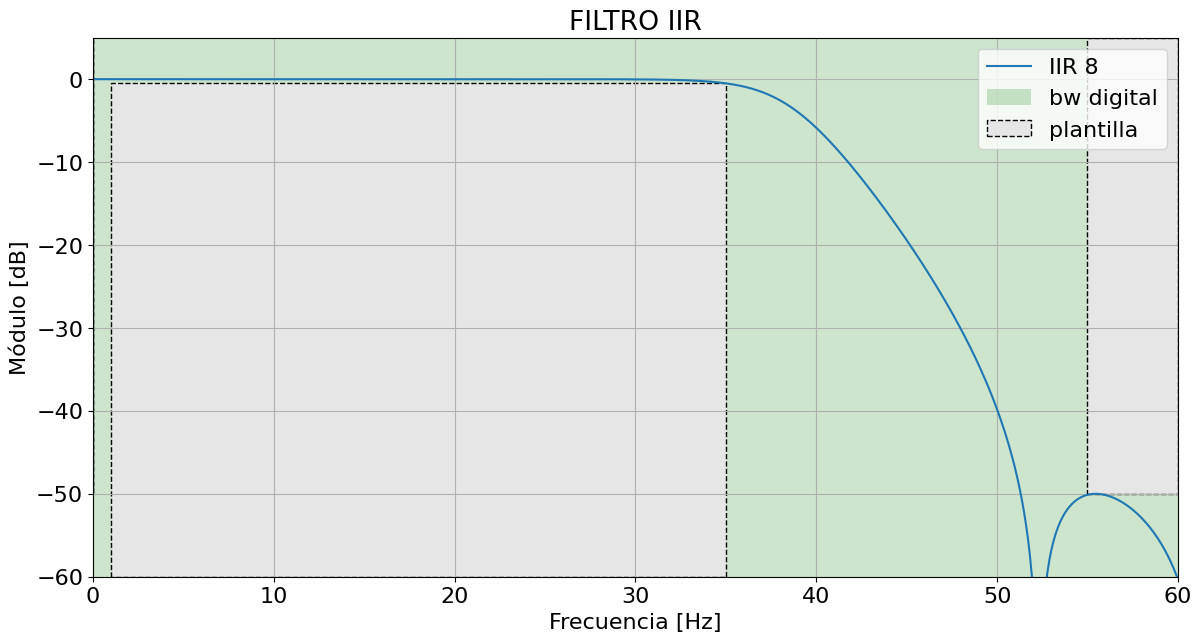

In [11]:
plt.figure(1, figsize=(fig_sz_x, fig_sz_y))

plt.plot(w_rad, 20*np.log10(np.abs(h_iir)+1e-12), label = 'IIR {:d}' .format(sos_iir.shape[0] * 2) )

plt.title('FILTRO IIR')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.grid()
plt.axis([0, 60, -60, 5 ])

axes_hdl = plt.gca()

plot_plantilla(filter_type = 'bandpass', fpass = (wp1, wp2), fstop =  (ws1, ws2), ripple = ripple, attenuation = atenuacion, fs = fs)
_ = axes_hdl.legend()

Con estos mismos pasos de diseño, se realizaron cambios en las frecuencias de corte utilizadas, al igual que en los valores de frecuencia de muestreo, atenuación y ripple, para ajustar el fitro antes desarrollado a las bandas de frecuencia que utiliza el Analizador de Espectro empleado en el presente laboratorio.

Con estos cambios, se diseñó el nuevo filtro a implementar.

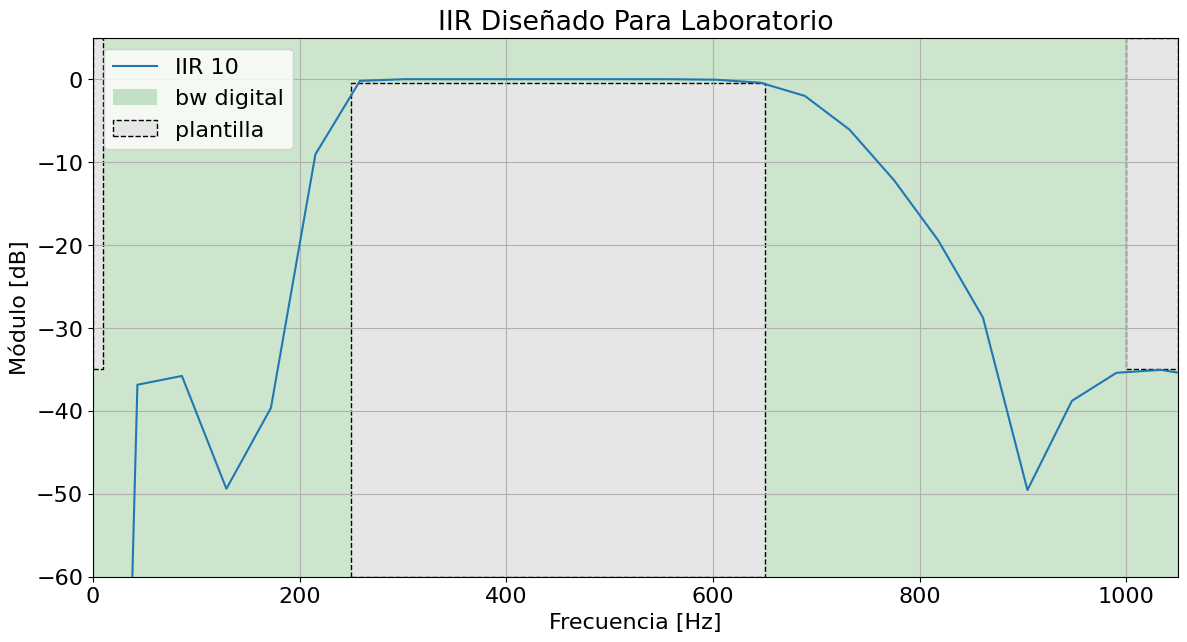

In [14]:
fs = 44100 # Hz
nyq_frec = fs / 2

# filter design
ripple = 0.5 # dB
atenuacion = 35 # dB

ws1 = 10 #Hz
wp1 = 250 #Hz
wp2 = 650 #Hz
ws2 = 1000 #Hz

sos_iir = sig.iirdesign(wp= [wp1,wp2], ws=[ws1,ws2], gpass=ripple, gstop=atenuacion, output='sos', analog=False, ftype='cheby2', fs = fs)

w_rad, h_iir = sig.freqz_sos(sos_iir, fs = fs)

plt.figure(1, figsize=(fig_sz_x, fig_sz_y))

plt.plot(w_rad, 20*np.log10(np.abs(h_iir)+1e-12), label = 'IIR {:d}' .format(sos_iir.shape[0] * 2))

plt.title('IIR Diseñado Para Laboratorio')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.grid()
plt.axis([0, 1050, -60, 5 ])

axes_hdl = plt.gca()

plot_plantilla(filter_type = 'bandpass', fpass = (wp1, wp2), fstop =  (ws1, ws2), ripple = ripple, attenuation = atenuacion, fs = fs)
_ = axes_hdl.legend()

Podemos observar que, en este caso, el filtro obtenido resulta ser de orden 10, lo que significa que puede descomponerse en 5 SOS o Secciones de Segundo Orden.

Una vez hecho esto, se agregaron la siguientes líneas de código para obtener los coeficientes del filtro diseñado. Se muestran, por un lado, los coeficientes del filtro en crudo, y luego en el formato que requiere la librería CMSIS para realizar el filtrado.

In [13]:
print('Coeficientes en crudo')

print(sos_iir)

print('\n')

print('Coeficientes en formato CMSIS')

# convertir a formato CMSIS
coeffs = []
for s in sos_iir:
    b0, b1, b2, a0, a1, a2 = s
    coeffs.extend([b0, b1, b2, -a1, -a2])  # sin a0

coeffs = np.array(coeffs, dtype=np.float64)  # mantener doble precisión

print(coeffs)

Coeficientes en crudo
[[ 0.00396553 -0.00779363  0.00396553  1.         -1.90970131  0.91285621]
 [ 1.          0.         -1.          1.         -1.91009039  0.91905394]
 [ 1.         -1.99968825  1.          1.         -1.96948659  0.97063314]
 [ 1.         -1.98316334  1.          1.         -1.96632277  0.97623235]
 [ 1.         -1.99935549  1.          1.         -1.99103573  0.99211521]]


Coeficientes en formato CMSIS
[ 0.00396553 -0.00779363  0.00396553  1.90970131 -0.91285621  1.
  0.         -1.          1.91009039 -0.91905394  1.         -1.99968825
  1.          1.96948659 -0.97063314  1.         -1.98316334  1.
  1.96632277 -0.97623235  1.         -1.99935549  1.          1.99103573
 -0.99211521]


Durante la práctica del laboratorio, surgieron varios inconvenientes en el curso en general al intentar compilar el proyecto suministrado por los profesores para realizar el filtrado con la placa STM NUCLEO-64, haciendo uso de su respectivo entorno de desarrollo.

Ante esta situación, los coeficientes obtenidos más arriba fueron enviados al profesor, quien sí pudo compilar el proyecto. Se logró observar en la pantalla del analizador de espectro una respuesta en frecuencia muy similar a la obtenida en el diseño, confirmando que nuestro desarrollo fue bastante acertado.